# BAS on OPFData: a finite-pool baseline

This notebook exercises bucketized acquisition over the **existing training split**. It keeps the original graphs and solver labels. The paper instead generates load vectors and solves them online; our experiment measures selection quality, not avoided solver time. See [README.md](README.md) for the reconstruction assumptions.

The small configuration is a software demonstration. Acquisition requires a plateau, so a short run may finish with no additions. That outcome is recorded rather than overridden.

In [1]:
from pathlib import Path
import json
import platform
import sys
import numpy as np
import pandas as pd
import torch
import torch_geometric

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'experiments/lumina_bench').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from distillation.BAS.run import configuration, implementation_identity, run, score_ids
from distillation.BAS.models import make_model
from distillation.BAS.aux.transfer import train_subset
from distillation.selection import TrainingPool, Buckets, allocate, ids_hash, selected_dataset
from distillation.training.T1_single_topo.common import digest
from distillation.training.T1_single_topo.data import CaseDataset
from distillation.training.T1_single_topo.state import Stop

torch.set_num_threads(1)
DEVICE = 'xpu:0' if torch.xpu.is_available() else 'cpu'
RUN_ROOT = ROOT / 'distillation/BAS/runs/notebook'
config = configuration(case='case30', model='MLP', buckets=8, panel_size=64,
    initial_size=32, max_selected=128, acquisition_size=32, batch_size=16,
    score_batch_size=16, max_rounds=10, validation_size=64,
    schedule=dict(minimum=1e-6, maximum=.01, decrease=.5, increase=2.,
                  patience_lr=1, patience_acquire=2))
display({'device': DEVICE, 'run_root': str(RUN_ROOT), 'config': config})

/opt/aurora/26.181.0/frameworks/aurora_frameworks-2026.1.0/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/aurora/26.181.0/frameworks/aurora_frameworks-2026.1.0/lib/python3.12/site-packages/torch/xpu/__init__.py:278: UserWarning: XPU device count is zero! (Triggered internally at /lus/tegu/projects/datasets/software/26.181.0/wheelforge/repositories/pytorch_2.13.0_patched_08_02_2026/pytorch/c10/xpu/XPUFunctions.cpp:117.)
  count = torch._C._xpu_getDeviceCount() if zes_count < 0 else zes_count


{'device': 'cpu',
 'run_root': '/home/siebenschuh/Projects/lumina-sdk/distillation/BAS/runs/notebook',
 'config': {'data_root': '/lus/flare/projects/FRAME-IDP/siebenschuh/acopf_datasets/processed/T1',
  'case': 'pglib_opf_case30_ieee',
  'split_seed': 42,
  'selection_seed': 42,
  'model_seed': 42,
  'deterministic': True,
  'model': 'MLP',
  'model_options': {'layers': 3, 'dropout': 0.1},
  'method': 'bas',
  'metric': 'ig',
  'loss': 'l1',
  'buckets': 8,
  'partition': 'quantile',
  'panel_size': 64,
  'initial_size': 32,
  'max_selected': 128,
  'acquisition_size': 32,
  'candidate_size': 5000,
  'mc_draws': 25,
  'batch_size': 16,
  'score_batch_size': 16,
  'epochs_per_round': 1,
  'max_rounds': 10,
  'validation_size': 64,
  'checkpoint_seconds': 120,
  'optimizer': {'lr': 0.001,
   'weight_decay': 0.01,
   'betas': [0.9, 0.999],
   'eps': 1e-08},
  'schedule': {'minimum': 1e-06,
   'maximum': 0.01,
   'decrease': 0.5,
   'increase': 2.0,
   'patience_lr': 1,
   'patience_acquir

The dataset loader supplies the same canonical 80/10/10 split used by the previous experiments. Model seed and selection seed are separate. Buckets and the labeled scoring panel use only train IDs; validation is reserved for reporting/checkpoint selection.

In [2]:
dataset = CaseDataset(config['data_root'], config['case'])
splits = dataset.splits(42)
display(pd.DataFrame([{'split': k, 'examples': len(v)} for k, v in splits.items()]))
# Keep each configuration/code/data/environment combination in its own directory.
# Identical reruns reuse the same directory; changed experiments preserve older runs.
identity = dict(config=config, data_identity=digest(dataset.manifest),
    split_hashes={k: ids_hash(v) for k, v in splits.items()},
    sources=implementation_identity(),
    environment=dict(torch=str(torch.__version__), pyg=torch_geometric.__version__,
                     numpy=np.__version__, python=platform.python_version(),
                     device_type=torch.device(DEVICE).type))
OUTPUT = RUN_ROOT / f'{config["case"]}_{digest(identity)[:16]}' / 'selection'
# The training-input cache lives in this experiment's parent directory too.
mode = ('verify completed run' if (OUTPUT / 'complete.json').exists() else
        'resume interrupted run' if (OUTPUT / 'latest.pt').exists() else 'start new run')
display({'action': mode, 'output': str(OUTPUT)})
with Stop(300) as stop:
    outcome = run(config, OUTPUT, device=DEVICE, stop=stop, dataset=dataset)
display(outcome)

,split,examples
0,train,240000
1,val,30000
2,test,30000


{'action': 'verify completed run',
 'output': '/home/siebenschuh/Projects/lumina-sdk/distillation/BAS/runs/notebook/pglib_opf_case30_ieee_905629b4f4ee4f41/selection'}

{'status': 'complete',
 'round': 10,
 'steps': 20,
 'presentations': 320,
 'selected': 32,
 'reference': 64,
 'acquisition_events': 0,
 'best_validation_l1': 10.579014644026756,
 'seconds': {'training': 3.372904146031942,
  'assessment': 10.343282313027885,
  'acquisition': 0.0},
 'wall_seconds': 14.920219129009638,
 'test_used': False,
 'artifacts': {'latest.pt': 'a7d370d41effbf1d0c6404b26f0442e0897a3bc52b8571583d4d717e6b4d5acd',
  'best.pt': '4af7dd86dcd15fee5a3cefd857fc5e48082d671e365ffb4b86cc3ef572096a6a',
  'selection.json': '12c80e9ab83cd3fb8f8be92b4e3139d8688429d8f452ac5436d104450d9476bb'}}

Identical reruns resume an interrupted run or verify completed artifacts. This notebook derives the output directory from the configuration, source files, dataset, exact split and execution environment. Changing one of those starts a separate run and displays its path; existing results are retained. The older `runs/notebook_case30` directory is preserved.

The strict checkpoint checks remain enabled. The checkpoint preserves optimizer, patience, RNG, acquisition history and the position within a training epoch. A source fingerprint change, including a new shared utility, must not silently mix experimental histories.

In [3]:
selection = json.loads((OUTPUT / 'selection.json').read_text())
partition = json.loads((OUTPUT / 'partition.json').read_text())
selected = selected_dataset(dataset, OUTPUT / 'selection.json')
assert set(selected.indices) <= set(splits['train'])
assert not set(selected.indices) & set(selection['pool']['reference_ids'])
assert not set(selected.indices) & (set(splits['val']) | set(splits['test']))
display({'selected_training_examples': len(selected),
         'reference_examples': selection['reference_count'],
         'selection_labels_accessed': selection['labeled_count'],
         'additional_validation_examples': config['validation_size'],
         'test_used': selection['test_used'], 'solver_calls': selection['solver_calls']})
coverage = pd.DataFrame({'train_pool': partition['training_counts'],
                        'reference_panel': partition['panel_counts'],
                        'selected': selection['selected_bucket_counts']})
coverage.index.name = 'bucket'
display(coverage)

{'selected_training_examples': 32,
 'reference_examples': 64,
 'selection_labels_accessed': 96,
 'additional_validation_examples': 64,
 'test_used': False,
 'solver_calls': 0}

,train_pool,reference_panel,selected
bucket,,,
0,30000,8,2
1,30000,8,6
2,30000,8,4
3,30000,8,5
4,29999,8,1
5,30001,8,6
6,30000,8,6
7,30000,8,2


The bucket coordinate is total active demand in per-unit, not an inferred version of the paper's regional multiplier. The following calculation inspects the next IG quotas at the saved state; it does not change the selected subset or bypass the scheduler.

In [4]:
saved = torch.load(OUTPUT / 'latest.pt', map_location='cpu', weights_only=False)
pool = TrainingPool(dataset, splits, saved['pool']['reference_ids'])
pool.load_state_dict(saved['pool'])
model = make_model(config, pool.inputs(pool.selected_ids[:1])[0], torch.device(DEVICE))
model.load_state_dict(saved['model'])
buckets = Buckets(np.asarray(partition['boundaries']), partition['strategy'])
index = torch.load(OUTPUT.parent / f'{config["case"]}_train_inputs.pt', weights_only=False)
membership = np.full(len(dataset), -1, dtype=np.int64)
membership[index['ids']] = buckets.assign(index['values'])
scores = score_ids(model, pool, pool.reference_ids, 'ig', config)
reference_bins = membership[pool.reference_ids]
means = np.bincount(reference_bins, weights=scores, minlength=buckets.count) / np.bincount(reference_bins, minlength=buckets.count)
capacity = np.bincount(membership[pool.remaining_ids], minlength=buckets.count)
budget = min(config['acquisition_size'], config['max_selected'] - len(pool.selected_ids))
display(pd.DataFrame({'mean_IG': means, 'available': capacity,
                      'prospective_quota': allocate(means, budget, capacity)}))

,mean_IG,available,prospective_quota
0,0.012513,29990,4
1,0.012631,29986,5
2,0.011944,29988,4
3,0.011448,29987,4
4,0.010383,29990,4
5,0.010826,29987,4
6,0.009448,29986,3
7,0.010270,29990,4


,round,training_count,selected_after,training_loss,panel_loss,learning_rate
0,0,32,32,44.860672,39.932053,0.001
1,1,32,32,39.634647,35.203794,0.001
2,2,32,32,35.382788,30.821848,0.001
3,3,32,32,30.994413,26.874537,0.001
4,4,32,32,27.766408,23.469930,0.001
5,5,32,32,23.972634,20.289554,0.001
6,6,32,32,21.307218,17.287990,0.001
7,7,32,32,18.741953,14.412099,0.001
8,8,32,32,16.164485,12.254843,0.001
9,9,32,32,14.592587,10.586825,0.001


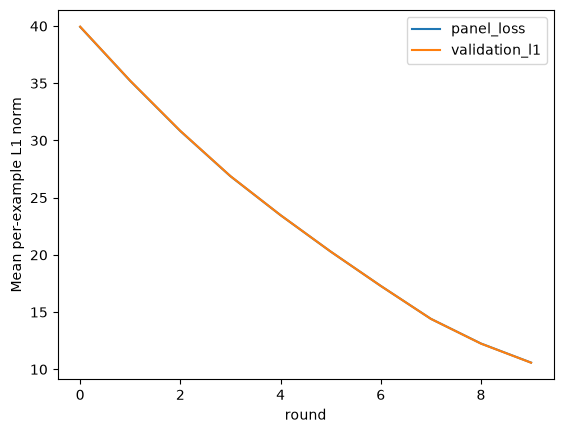

In [5]:
history = pd.DataFrame([json.loads(p.read_text()) for p in sorted((OUTPUT / 'history').glob('*.json'))])
if not history.empty:
    display(history[['round', 'training_count', 'selected_after', 'training_loss', 'panel_loss', 'learning_rate']])
    history.assign(validation_l1=history.validation.map(lambda x: x['l1'])).plot(
        x='round', y=['panel_loss', 'validation_l1'], ylabel='Mean per-example L1 norm')

Finally, initialize a fresh student for the frozen subset and another for a same-size random subset. Both use the same seed, training budget, optimizer and validation IDs. Two epochs only check the workflow; useful comparisons need larger budgets and multiple seeds. Test data is unopened.

In [6]:
if outcome['status'] == 'complete':
    controls = []
    for random_control in (False, True):
        folder = OUTPUT / ('fresh_random' if random_control else 'fresh_selected')
        with Stop(120) as stop:
            controls.append(train_subset(OUTPUT / 'selection.json', folder,
                model='MLP', seed=100, epochs=2, device=DEVICE,
                random_control=random_control, stop=stop))
    display(pd.DataFrame(controls))

,status,selected,seed,model,random_control,best_validation_l1,test_used
0,complete,32,100,MLP,False,33.504717,False
1,complete,32,100,MLP,True,33.518140,False
